# Simple VAE-style

In [1]:
import torch
import torch.nn as nn

class VAE(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU()
        )

        # Mean and log variance
        self.fc_mu = nn.Linear(128, 20)
        self.fc_logvar = nn.Linear(128, 20)

        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(20, 128),
            nn.ReLU(),
            nn.Linear(128, 28 * 28),
            nn.Sigmoid()
        )

    def forward(self, x):
        h = self.encoder(x)

        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)

        # Sampling
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)

        z = mu + eps * std

        output = self.decoder(z)

        return output, mu, logvar

# Simple GAN

In [2]:
import torch
import torch.nn as nn

# Generator
class Generator(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.Linear(100, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid()
        )

    def forward(self, z):
        return self.model(z)


# Discriminator
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)

In [3]:
z = torch.randn(1, 100)

G = Generator()

fake_image = G(z)

print(fake_image.shape)

torch.Size([1, 784])


# Adding Noise

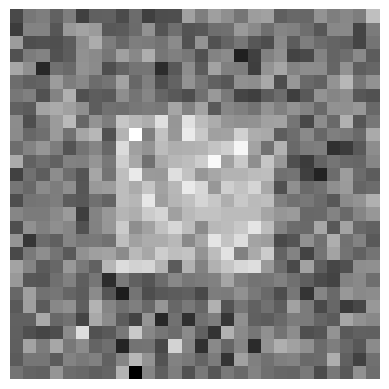

In [4]:
import torch
import matplotlib.pyplot as plt

# Create a simple image
image = torch.zeros(28, 28)

# Put a white square in the center
image[8:20, 8:20] = 1.0

# Add Gaussian noise
noise = torch.randn_like(image)

noisy_image = image + 0.5 * noise

# Display
plt.imshow(noisy_image, cmap="gray")
plt.axis("off")
plt.show()

# Noise Levels

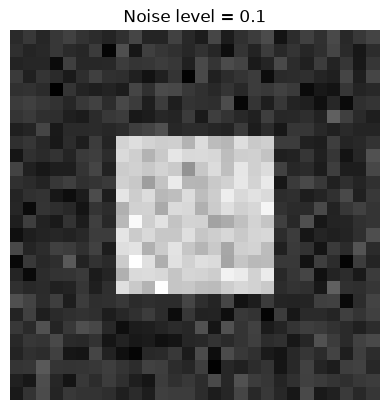

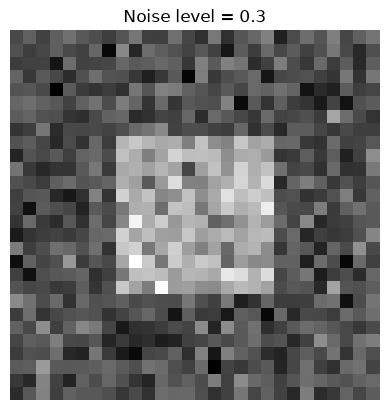

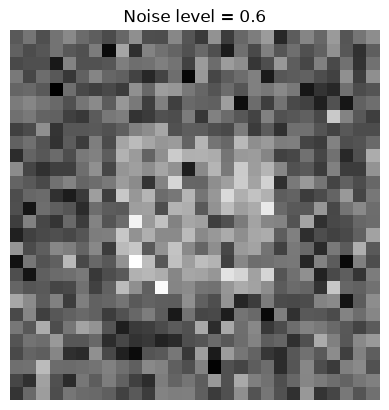

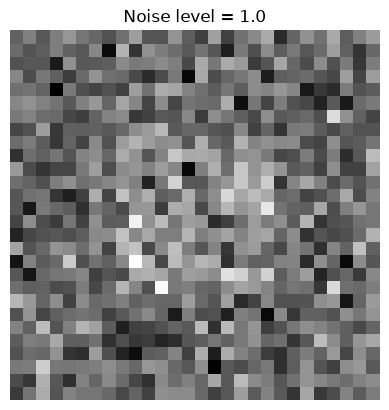

In [5]:
import torch
import matplotlib.pyplot as plt

image = torch.zeros(28, 28)
image[8:20, 8:20] = 1.0

noise = torch.randn_like(image)

levels = [0.1, 0.3, 0.6, 1.0]

for level in levels:
    noisy = image + level * noise

    plt.figure()
    plt.imshow(noisy, cmap="gray")
    plt.title(f"Noise level = {level}")
    plt.axis("off")
    plt.show()

# Simple Forward Diffusion

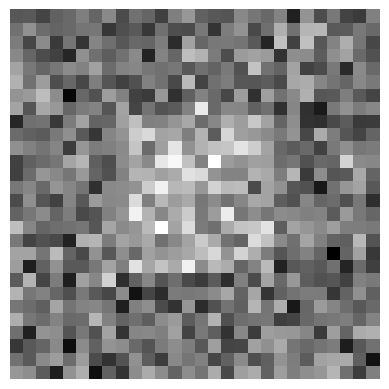

In [6]:
import torch
import matplotlib.pyplot as plt

# Simple 28x28 image
x0 = torch.zeros(28, 28)

# Create a white square
x0[8:20, 8:20] = 1.0

# Noise level
beta = 0.3

# Random Gaussian noise
epsilon = torch.randn_like(x0)

# Add noise
xt = torch.sqrt(torch.tensor(1 - beta)) * x0 + \
     torch.sqrt(torch.tensor(beta)) * epsilon

# Show image
plt.imshow(xt, cmap="gray")
plt.axis("off")
plt.show()

# Multiple Diffusion Steps

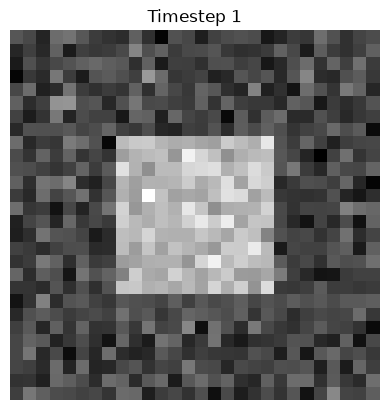

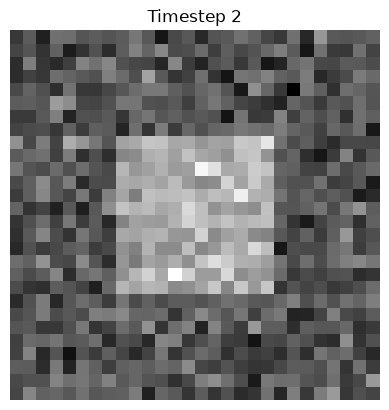

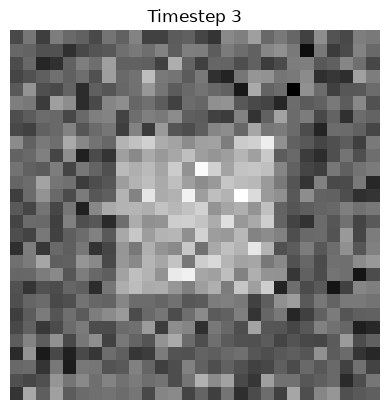

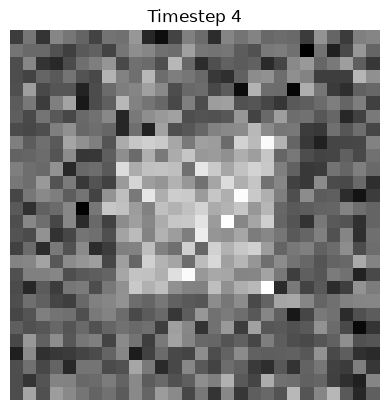

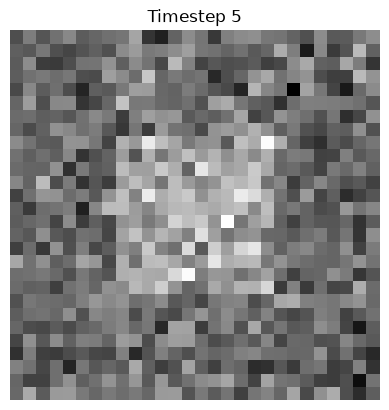

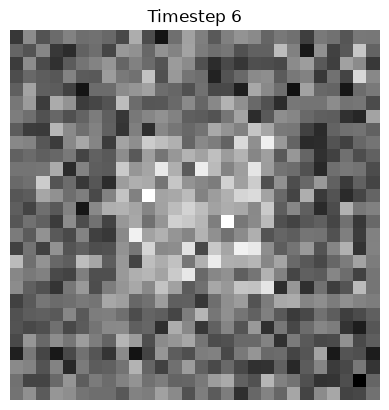

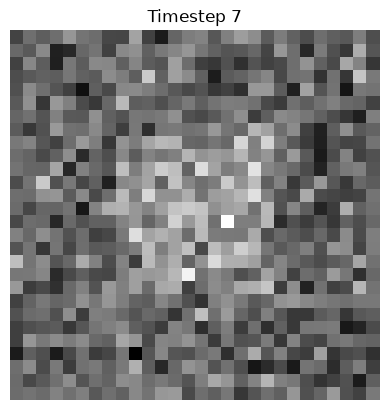

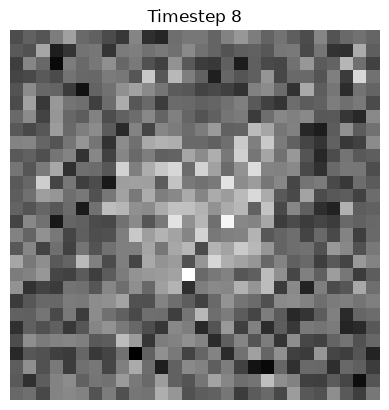

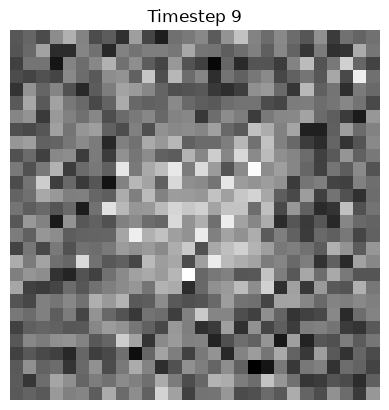

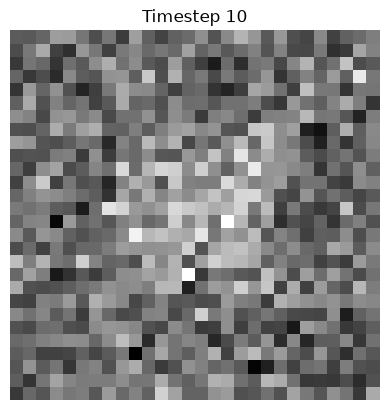

In [7]:
import torch
import matplotlib.pyplot as plt

x = torch.zeros(28, 28)
x[8:20, 8:20] = 1.0

for t in range(10):

    beta = 0.05

    noise = torch.randn_like(x)

    x = torch.sqrt(torch.tensor(1 - beta)) * x + \
        torch.sqrt(torch.tensor(beta)) * noise

    plt.figure()
    plt.imshow(x, cmap="gray")
    plt.title(f"Timestep {t + 1}")
    plt.axis("off")
    plt.show()

In [8]:
import torch
import torch.nn as nn

# Very simple model
model = nn.Sequential(
    nn.Linear(28 * 28, 256),
    nn.ReLU(),
    nn.Linear(256, 28 * 28)
)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fn = nn.MSELoss()

# Original image
x0 = torch.randn(1, 28 * 28)

# Random noise
noise = torch.randn_like(x0)

# Create noisy image
xt = x0 + 0.5 * noise

# Model predicts noise
predicted_noise = model(xt)

# Compare predicted vs actual noise
loss = loss_fn(predicted_noise, noise)

optimizer.zero_grad()
loss.backward()
optimizer.step()

print("Loss:", loss.item())

Loss: 1.1906245946884155


# Prepare an image

In [9]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])

dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True
)

images, labels = next(iter(loader))

print("Images:", images.shape)
print("Labels:", labels.shape)

Images: torch.Size([32, 3, 64, 64])
Labels: torch.Size([32])


# Forward Process PyTorch example

In [10]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Prepare images
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])

# Download CIFAR-10
dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True
)

images, labels = next(iter(loader))

print(images.shape)

noise = torch.randn_like(images)

noise_strength = 0.5

noisy_images = (
    images * (1 - noise_strength)
    + noise * noise_strength
)

print(noisy_images.shape)

torch.Size([32, 3, 64, 64])
torch.Size([32, 3, 64, 64])


# Multiple diffusion steps

In [11]:
noise = torch.randn_like(images)

for t in [0.1, 0.3, 0.5, 0.7, 0.9]:

    noisy = (
        images * (1 - t)
        + noise * t
    )

    print("Noise level:", t)

Noise level: 0.1
Noise level: 0.3
Noise level: 0.5
Noise level: 0.7
Noise level: 0.9


# Real DDPM-style implementation

In [12]:
import torch

def forward_diffusion(x0, alpha_bar):
    """
    x0        = clean image
    alpha_bar = amount of original image remaining
    """

    noise = torch.randn_like(x0)

    xt = (
        torch.sqrt(alpha_bar) * x0
        + torch.sqrt(1 - alpha_bar) * noise
    )

    return xt, noise

alpha_bar = torch.tensor(0.7)

xt, noise = forward_diffusion(
    images,
    alpha_bar
)

print("Clean image:", images.shape)
print("Noisy image:", xt.shape)
print("Noise:", noise.shape)

Clean image: torch.Size([32, 3, 64, 64])
Noisy image: torch.Size([32, 3, 64, 64])
Noise: torch.Size([32, 3, 64, 64])


# Loss

In [13]:
import torch
import torch.nn as nn

loss_fn = nn.MSELoss()

actual_noise = torch.tensor([0.2, -0.5, 0.8])

predicted_noise = torch.tensor([0.3, -0.4, 0.6])

loss = loss_fn(predicted_noise, actual_noise)

print("Loss:", loss.item())

Loss: 0.019999997690320015


# Small Training Example

In [14]:
import torch
import torch.nn as nn
import torch.optim as optim

# Simple model
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(3 * 64 * 64, 512),
    nn.ReLU(),
    nn.Linear(512, 3 * 64 * 64)
)

# Loss
loss_fn = nn.MSELoss()

# Optimizer
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# Example clean images
x0 = torch.randn(8, 3, 64, 64)

# Random noise
noise = torch.randn_like(x0)

# Create noisy images
alpha_bar = 0.7

xt = (
    torch.sqrt(torch.tensor(alpha_bar)) * x0
    + torch.sqrt(torch.tensor(1 - alpha_bar)) * noise
)

# Model predicts noise
predicted_noise = model(xt)

# Reshape
predicted_noise = predicted_noise.view_as(noise)

# Calculate loss
loss = loss_fn(predicted_noise, noise)

# Backpropagation
optimizer.zero_grad()
loss.backward()
optimizer.step()

print("Loss:", loss.item())

Loss: 1.0646700859069824


# Training for Many Epochs

In [15]:
for epoch in range(10):

    total_loss = 0

    for x0, _ in loader:

        # Random noise
        noise = torch.randn_like(x0)

        # Create noisy image
        alpha_bar = 0.7

        xt = (
            torch.sqrt(torch.tensor(alpha_bar)) * x0
            + torch.sqrt(torch.tensor(1 - alpha_bar)) * noise
        )

        # Predict noise
        predicted_noise = model(xt)
        predicted_noise = predicted_noise.view_as(noise)

        # Loss
        loss = loss_fn(predicted_noise, noise)

        # Update model
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(
        f"Epoch {epoch+1}, "
        f"Loss: {total_loss / len(loader):.4f}"
    )

Epoch 1, Loss: 1.0223


KeyboardInterrupt: 

# Sampling

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# -----------------------------------
# 1. Simple noise-prediction model
# -----------------------------------

class SimpleDenoiser(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3 * 32 * 32, 512),
            nn.ReLU(),
            nn.Linear(512, 3 * 32 * 32)
        )

    def forward(self, x):
        out = self.net(x)
        return out.view_as(x)


model = SimpleDenoiser()

# -----------------------------------
# 2. Sampling function
# -----------------------------------

def sample(model, steps=100):

    # Start from pure random noise
    x = torch.randn(1, 3, 32, 32)

    model.eval()

    with torch.no_grad():

        for step in reversed(range(steps)):

            # Predict noise
            predicted_noise = model(x)

            # Remove a small amount of predicted noise
            x = x - 0.01 * predicted_noise

    return x


# -----------------------------------
# 3. Generate image
# -----------------------------------

generated = sample(model)

print("Generated shape:", generated.shape)

In [ ]:
# Convert image for displaying

image = generated[0].permute(1, 2, 0)

# Normalize for display
image = (image - image.min()) / (image.max() - image.min())

plt.imshow(image)
plt.axis("off")
plt.show()

# Full Diffusion Model

## Imports + Setup

In [ ]:
# If needed in Colab:
# !pip install torch torchvision matplotlib tqdm

import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

## Device

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using:", device)

## Setting Up the Data(CIFAR-10)

In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),

    # Convert [0, 1] → [-1, 1]
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])

dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

loader = DataLoader(
    dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Dataset size:", len(dataset))

In [ ]:
images, labels = next(iter(loader))

print("Image shape:", images.shape)
print("Label shape:", labels.shape)
print("Min:", images.min().item())
print("Max:", images.max().item())

## Display Original Images

In [ ]:
def show_images(images, title="Images"):

    images = images.detach().cpu()

    # [-1, 1] → [0, 1]
    images = (images + 1) / 2
    images = images.clamp(0, 1)

    grid = torch.cat(
        [img for img in images[:16]],
        dim=2
    )

    # Easier: use torchvision grid
    from torchvision.utils import make_grid

    grid = make_grid(
        images[:16],
        nrow=4
    )

    plt.figure(figsize=(6, 6))
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis("off")
    plt.title(title)
    plt.show()


show_images(images, "Original CIFAR-10 Images")

## The Forward Process

In [ ]:
T = 1000

beta_start = 1e-4
beta_end = 0.02

betas = torch.linspace(
    beta_start,
    beta_end,
    T,
    device=device
)

alphas = 1.0 - betas

alpha_bars = torch.cumprod(
    alphas,
    dim=0
)

print("betas:", betas.shape)
print("alphas:", alphas.shape)
print("alpha_bars:", alpha_bars.shape)

## Forward Diffusion Function

In [ ]:
def forward_diffusion(x0, t):

    noise = torch.randn_like(x0)

    alpha_bar_t = alpha_bars[t]

    sqrt_alpha_bar = torch.sqrt(alpha_bar_t)
    sqrt_one_minus_alpha_bar = torch.sqrt(
        1 - alpha_bar_t
    )

    # Make shape [batch, 1, 1, 1]
    sqrt_alpha_bar = sqrt_alpha_bar[:, None, None, None]
    sqrt_one_minus_alpha_bar = (
        sqrt_one_minus_alpha_bar[:, None, None, None]
    )

    xt = (
        sqrt_alpha_bar * x0
        +
        sqrt_one_minus_alpha_bar * noise
    )

    return xt, noise

## Test Forward Diffusion

In [ ]:
images = images.to(device)

# Different timesteps
timesteps = torch.tensor(
    [0, 100, 300, 500, 700, 900],
    device=device
)

# Use same first image multiple times
x0 = images[0:1].repeat(
    len(timesteps), 1, 1, 1
)

noisy_images, noise = forward_diffusion(
    x0,
    timesteps
)

print(noisy_images.shape)

## Display

In [ ]:
from torchvision.utils import make_grid

display_images = (noisy_images + 1) / 2
display_images = display_images.clamp(0, 1)

grid = make_grid(
    display_images,
    nrow=6
)

plt.figure(figsize=(15, 3))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.title("Forward Diffusion: t = 0 → 900")
plt.show()

## Training Timestep Embedding

In [ ]:
class TimeEmbedding(nn.Module):

    def __init__(self, dim):

        super().__init__()

        self.dim = dim

    def forward(self, t):

        half = self.dim // 2

        emb = math.log(10000) / (half - 1)

        emb = torch.exp(
            torch.arange(
                half,
                device=t.device
            ) * -emb
        )

        emb = t.float()[:, None] * emb[None, :]

        emb = torch.cat(
            [emb.sin(), emb.cos()],
            dim=1
        )

        return emb

## Simple Residual Block

In [ ]:
class Block(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        time_dim
    ):

        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

        self.norm1 = nn.GroupNorm(
            8,
            out_channels
        )

        self.norm2 = nn.GroupNorm(
            8,
            out_channels
        )

        self.time_mlp = nn.Linear(
            time_dim,
            out_channels
        )

        self.activation = nn.SiLU()

        self.residual = (
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1
            )
            if in_channels != out_channels
            else nn.Identity()
        )

    def forward(self, x, t):

        h = self.conv1(x)
        h = self.norm1(h)
        h = self.activation(h)

        time_embedding = self.time_mlp(t)

        h = h + time_embedding[:, :, None, None]

        h = self.conv2(h)
        h = self.norm2(h)
        h = self.activation(h)

        return h + self.residual(x)

## Small U-Net

In [ ]:
class SmallUNet(nn.Module):

    def __init__(self):

        super().__init__()

        time_dim = 128

        self.time_embedding = TimeEmbedding(
            time_dim
        )

        # Encoder
        self.block1 = Block(
            3,
            64,
            time_dim
        )

        self.down1 = nn.Conv2d(
            64,
            128,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.block2 = Block(
            128,
            128,
            time_dim
        )

        self.down2 = nn.Conv2d(
            128,
            256,
            kernel_size=4,
            stride=2,
            padding=1
        )

        # Middle
        self.middle = Block(
            256,
            256,
            time_dim
        )

        # Decoder
        self.up1 = nn.ConvTranspose2d(
            256,
            128,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.block3 = Block(
            128 + 128,
            128,
            time_dim
        )

        self.up2 = nn.ConvTranspose2d(
            128,
            64,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.block4 = Block(
            64 + 64,
            64,
            time_dim
        )

        self.output = nn.Conv2d(
            64,
            3,
            kernel_size=1
        )

    def forward(self, x, t):

        t_emb = self.time_embedding(t)

        # Encoder
        e1 = self.block1(x, t_emb)

        e2 = self.down1(e1)
        e2 = self.block2(e2, t_emb)

        # Middle
        m = self.down2(e2)
        m = self.middle(m, t_emb)

        # Decoder
        d1 = self.up1(m)

        d1 = torch.cat(
            [d1, e2],
            dim=1
        )

        d1 = self.block3(
            d1,
            t_emb
        )

        d2 = self.up2(d1)

        d2 = torch.cat(
            [d2, e1],
            dim=1
        )

        d2 = self.block4(
            d2,
            t_emb
        )

        return self.output(d2)

## Create Model

In [ ]:
model = SmallUNet().to(device)

print(
    "Parameters:",
    sum(p.numel() for p in model.parameters())
)

## MSE Loss

In [ ]:
images, labels = next(iter(loader))

images = images.to(device)

batch_size = images.shape[0]

# Random timestep for each image
t = torch.randint(
    0,
    T,
    (batch_size,),
    device=device
)

# Forward diffusion
xt, actual_noise = forward_diffusion(
    images,
    t
)

# Predict noise
predicted_noise = model(
    xt,
    t
)

# MSE loss
loss = loss_fn(
    predicted_noise,
    actual_noise
)

print("Loss:", loss.item())

## Full Training Loop

## Reverse Diffusion Function

In [ ]:
@torch.no_grad()
def sample(model, n_images=16):

    model.eval()

    # Start from pure Gaussian noise
    x = torch.randn(
        n_images,
        3,
        32,
        32,
        device=device
    )

    for t_value in tqdm(
        reversed(range(T)),
        total=T,
        desc="Sampling"
    ):

        t = torch.full(
            (n_images,),
            t_value,
            device=device,
            dtype=torch.long
        )

        # Predict noise
        predicted_noise = model(
            x,
            t
        )

        beta_t = betas[t_value]
        alpha_t = alphas[t_value]
        alpha_bar_t = alpha_bars[t_value]

        # DDPM reverse mean
        x = (
            1 / torch.sqrt(alpha_t)
        ) * (
            x
            -
            (
                beta_t
                /
                torch.sqrt(
                    1 - alpha_bar_t
                )
            )
            * predicted_noise
        )

        # Add random noise except at final step
        if t_value > 0:

            noise = torch.randn_like(x)

            x = x + torch.sqrt(
                beta_t
            ) * noise

    return x

## Generate Images

In [ ]:
generated_images = sample(
    model,
    n_images=16
)

print(generated_images.shape)

## Display Generated Images

In [ ]:
generated_images = (
    generated_images + 1
) / 2

generated_images = generated_images.clamp(
    0,
    1
)

grid = make_grid(
    generated_images,
    nrow=4
)

plt.figure(figsize=(7, 7))

plt.imshow(
    grid.permute(1, 2, 0)
)

plt.axis("off")
plt.title("Generated Images")

plt.show()

## Save and Load 

In [ ]:
torch.save(
    model.state_dict(),
    "diffusion_model.pth"
)

print("Model saved!")

model.load_state_dict(
    torch.load(
        "diffusion_model.pth",
        map_location=device
    )
)

model.to(device)

print("Model loaded!")